# LASV glycoprotein peptide responses positively associated with neutralization

Primary analysis in baseline **confirmed Lassa fever survivors** with matched PhIP-Seq and continuous neutralization measurements.

This notebook intentionally focuses on the directional biological question: **which LASV glycoprotein (GPC) peptide responses are associated with greater neutralization potency?** Two-sided tests are performed and FDR correction is applied across all tested peptides; only **positive-direction** associations are retained as candidate neutralization-associated responses.

Workflow:
1. Unbiased two-sided peptide screen against continuous neutralization.
2. BH-FDR across all tested LASV GPC peptides, then retain only positive-effect hits.
3. Adjusted models controlling for age, sex, and years since discharge.
4. Secondary GP-ELISA-adjusted models to test whether peptide specificity contributes beyond overall GP-binding magnitude.
5. Collapse/inspect sequence-related positive hits as candidate epitope regions.
6. Region-level neutralization analysis for sequence-similar positive hits.


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

# ---------- paths ----------
META_FILE = Path('./metadata_files/master_sample_metadata_111226.csv')
LONG_FILE = Path('./output_files/long_spec_0_98_111226.csv')
PEP_META_FILE = Path('./metadata_files/lassa_library_sequences_species_standardized_070726_ICTV_corrected.csv')
OUTDIR = Path('./output_figures')
OUTDIR.mkdir(parents=True, exist_ok=True)

# ---------- publication style ----------
plt.rcParams.update({
    'font.size': 9, 'axes.labelsize': 10, 'axes.titlesize': 11,
    'xtick.labelsize': 9, 'ytick.labelsize': 9, 'legend.fontsize': 9,
    'axes.spines.top': False, 'axes.spines.right': False,
    'svg.fonttype': 'none', 'pdf.fonttype': 42,
})
SURVIVOR_COLOR = '#D55E00'


In [3]:
# Load data
sample_meta = pd.read_csv(META_FILE)
df = pd.read_csv(LONG_FILE)
peps_meta = pd.read_csv(PEP_META_FILE)
peps_metadata = peps_meta.set_index('seq_id')

# Dates and baseline sample per participant
sample_meta['collection_date'] = pd.to_datetime(sample_meta['collection_date'], errors='coerce')
sample_meta['discharge_date'] = pd.to_datetime(sample_meta['discharge_date'], errors='coerce')

sample_meta_baseline = (
    sample_meta.sort_values(['participant_id', 'collection_date'])
    .drop_duplicates('participant_id', keep='first')
    .copy()
)

# Confirmed survivors with neutralization data
surv = sample_meta_baseline.loc[
    (sample_meta_baseline['Category'].astype(str).str.upper() == 'S') &
    sample_meta_baseline['Neut_Percent'].notna()
].copy()

# statsmodels compatibility
if 'sex' in surv.columns:
    surv['sex_model'] = surv['sex'].astype(object)

for col in ['Neut_Percent','GP_Calc_Conc','age_years','years_since_discharge']:
    if col in surv.columns:
        surv[col] = pd.to_numeric(surv[col], errors='coerce')

print('Baseline survivors with neutralization:', len(surv))
print(surv[['Neut_Percent','GP_Calc_Conc','age_years','years_since_discharge']].describe())
print()
print('Sex:')
print(surv['sex_model'].value_counts(dropna=False) if 'sex_model' in surv else 'sex unavailable')


Baseline survivors with neutralization: 125
       Neut_Percent  GP_Calc_Conc   age_years  years_since_discharge
count    125.000000    125.000000  103.000000              88.000000
mean      65.329663     10.594133   31.805825              10.341250
std       27.340278     18.861111   13.737068               7.803963
min        0.000000      0.505755    7.000000               0.050000
25%       50.650698      1.667662   20.000000               3.715000
50%       72.976664      4.229209   32.000000               9.090000
75%       86.166650     11.197223   40.000000              15.455000
max       95.695282    133.726960   75.000000              29.480000

Sex:
sex_model
Female    78
Male      43
NaN        4
Name: count, dtype: int64


/tmp/ipykernel_3727927/1599332109.py:8: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  sample_meta['collection_date'] = pd.to_datetime(sample_meta['collection_date'], errors='coerce')
/tmp/ipykernel_3727927/1599332109.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  sample_meta['discharge_date'] = pd.to_datetime(sample_meta['discharge_date'], errors='coerce')


In [4]:
# Restrict long PhIP data to survivor baseline samples and LASV glycoprotein only
survivor_ids = set(surv['sample_id'])
lasv = df.loc[
    df['individual'].isin(survivor_ids) &
    df['species'].eq('Mammarenavirus lassaense') &
    df['protein_std'].eq('glycoprotein')
].copy()

print('PhIP survivor samples:', lasv['individual'].nunique())
print('LASV GPC peptides tested:', lasv['peptide'].nunique())
print('PhIP survivor samples with GPC data:', lasv['individual'].nunique())


PhIP survivor samples: 118
LASV GPC peptides tested: 16
PhIP survivor samples with GPC data: 118


In [5]:
# QC: this notebook must contain GPC only
assert lasv['protein_std'].eq('glycoprotein').all()
print('Proteins in analysis:', lasv['protein_std'].unique())
print('GPC peptides:', lasv['peptide'].nunique())
print('Survivors represented:', lasv['individual'].nunique())


Proteins in analysis: ['glycoprotein']
GPC peptides: 16
Survivors represented: 118


## 1. GPC peptide-level screen against continuous neutralization
For each **LASV glycoprotein peptide**, compare neutralization percentage in peptide-reactive versus peptide-nonreactive survivors using a two-sided Mann–Whitney U test. BH-FDR is applied only across the prespecified LASV GPC peptide family. Directional filtering (`delta_median_neut > 0`) is applied only after FDR correction.


In [6]:
assert lasv['protein_std'].eq('glycoprotein').all()

meta_neut = surv[['sample_id','participant_id','Neut_Percent','GP_Calc_Conc','age_years','years_since_discharge','sex_model']].copy()
lasv_neut = lasv.merge(meta_neut, left_on='individual', right_on='sample_id', how='left', validate='many_to_one')

rows = []
for peptide, g in lasv_neut.groupby('peptide'):
    g = g.drop_duplicates('individual').dropna(subset=['Neut_Percent'])
    pos = g.loc[g['reactive'].astype(bool), 'Neut_Percent']
    neg = g.loc[~g['reactive'].astype(bool), 'Neut_Percent']
    if len(pos) < 3 or len(neg) < 3:
        continue

    # Keep the hypothesis test two-sided. Direction is handled AFTER FDR correction.
    stat, p = mannwhitneyu(pos, neg, alternative='two-sided')

    rows.append({
        'peptide': peptide,
        'protein_std': g['protein_std'].iloc[0],
        'n_reactive': len(pos),
        'n_nonreactive': len(neg),
        'median_neut_reactive': pos.median(),
        'median_neut_nonreactive': neg.median(),
        'delta_median_neut': pos.median() - neg.median(),
        'mean_neut_reactive': pos.mean(),
        'mean_neut_nonreactive': neg.mean(),
        'p_screen': p
    })

screen = pd.DataFrame(rows)
screen['FDR_screen'] = multipletests(screen['p_screen'], method='fdr_bh')[1]
screen['positive_direction'] = screen['delta_median_neut'] > 0
screen['positive_FDR05'] = (screen['FDR_screen'] < 0.05) & screen['positive_direction']
screen = screen.sort_values(['FDR_screen','p_screen']).reset_index(drop=True)

# annotate sequence/accession/species
ann = peps_metadata[['sequence','accession','species']].copy()
screen = screen.merge(ann, left_on='peptide', right_index=True, how='left')

positive_hits = screen.loc[screen['positive_FDR05']].copy().sort_values(
    ['FDR_screen','delta_median_neut'], ascending=[True, False]
)

print('Tested GPC peptides:', len(screen))
print('All FDR < 0.05 (either direction):', (screen['FDR_screen'] < 0.05).sum())
print('Positive-direction FDR < 0.05:', len(positive_hits))
display(positive_hits.head(30))


Tested GPC peptides: 16
All FDR < 0.05 (either direction): 11
Positive-direction FDR < 0.05: 11


,peptide,protein_std,n_reactive,n_nonreactive,median_neut_reactive,median_neut_nonreactive,delta_median_neut,mean_neut_reactive,mean_neut_nonreactive,p_screen,FDR_screen,positive_direction,positive_FDR05,sequence,accession,species
0,AZI96412.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,31,87,86.988617,65.452147,21.536470,85.948665,59.843794,2.281017e-08,3.649627e-07,True,True,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPKCWLVSNGS,AZI96412.1,Mammarenavirus lassaense
1,AZI96059.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,33,85,86.533287,65.563298,20.969990,84.199426,59.908677,4.045239e-07,3.236191e-06,True,True,NDQLIMKNHLRDIMGIPYCNYSKYWYLNNTVTGKSSLPKCWLVSNG,AZI96059.1,Mammarenavirus lassaense
2,AZI96476.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,37,81,86.166650,67.722491,18.444158,82.018692,59.705272,1.100137e-06,5.867396e-06,True,True,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTITGKTSLPRCWLVSNGS,AZI96476.1,Mammarenavirus lassaense
3,AZI96488.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,37,81,85.841573,67.242783,18.598790,81.865400,59.775294,3.775321e-06,1.510129e-05,True,True,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPRCWLVSNGT,AZI96488.1,Mammarenavirus lassaense
4,AHC95553.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,24,94,87.618931,68.569823,19.049108,85.579305,61.882078,6.488869e-06,2.076438e-05,True,True,TSLPKCWLVSNGSYLNETHFSDDIEQQADNMITEMLQKEYMDRQGK,AHC95553.1,Mammarenavirus lassaense
6,ANH09740.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,49,69,84.984398,64.203796,20.780602,79.587083,57.551472,1.521094e-05,3.428517e-05,True,True,CNEKHDEEFCDMWRLFDFNKQAIQRLKAEAQMNIQLINKAVNALIN,ANH09740.1,Mammarenavirus lassaense
5,XBA96065.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,52,66,84.484379,63.994275,20.490105,78.576977,57.345695,1.446256e-05,3.428517e-05,True,True,KCNEKHDEEFCDMLRLFDFNKQAIQRLKAEAQMSIQLINKAVNALI,XBA96065.1,Mammarenavirus lassaense
7,AZI96488.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,24,94,87.695808,69.534578,18.161230,82.303663,62.718412,1.714259e-05,3.428517e-05,True,True,WYLNHTVTGKTSLPRCWLVSNGTYLNETHFSDDIEQQADNMITELL,AZI96488.1,Mammarenavirus lassaense
8,AZI96059.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,18,100,87.908520,69.534578,18.373942,87.163824,63.018698,3.426302e-05,6.091204e-05,True,True,YWYLNNTVTGKSSLPKCWLVSNGSYLNETHFSEDIEQQADNMITEM,AZI96059.1,Mammarenavirus lassaense
9,AZI96476.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,23,95,86.988617,70.310479,16.678138,79.737259,63.545913,5.509087e-04,8.814540e-04,True,True,WYLNHTITGKTSLPRCWLVSNGSYLNETQFSDDIEQQADNMITELL,AZI96476.1,Mammarenavirus lassaense


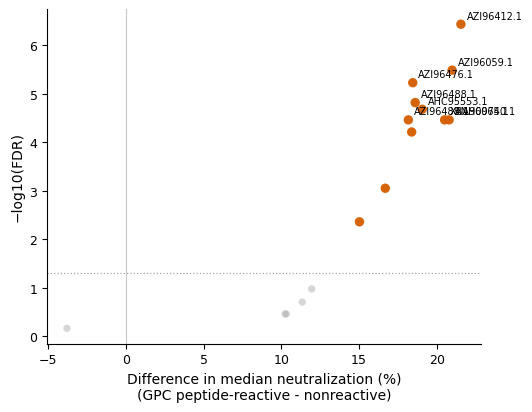

In [7]:
# Discovery plot: effect size vs significance
# All tested GPC peptides are shown, but only significant POSITIVE associations are highlighted/labeled.
plot_df = screen.copy()
plot_df['minus_log10_FDR'] = -np.log10(plot_df['FDR_screen'].clip(lower=1e-300))

fig, ax = plt.subplots(figsize=(5.4, 4.2))
ax.scatter(
    plot_df['delta_median_neut'], plot_df['minus_log10_FDR'],
    s=28, alpha=0.45, color='0.65', edgecolor='none'
)

sig_pos = plot_df['positive_FDR05']
ax.scatter(
    plot_df.loc[sig_pos,'delta_median_neut'],
    plot_df.loc[sig_pos,'minus_log10_FDR'],
    s=46, alpha=0.95, color=SURVIVOR_COLOR, edgecolor='none'
)

ax.axhline(-np.log10(0.05), color='0.65', lw=0.9, ls=':')
ax.axvline(0, color='0.78', lw=0.8)
ax.set_xlabel('Difference in median neutralization (%)\n(GPC peptide-reactive - nonreactive)')
ax.set_ylabel('−log10(FDR)')

# Label only the strongest positive-direction hits
for _, r in positive_hits.head(8).iterrows():
    short = str(r['accession']) if pd.notna(r['accession']) else str(r['peptide'])[:12]
    ax.annotate(
        short,
        (r['delta_median_neut'], -np.log10(max(r['FDR_screen'], 1e-300))),
        xytext=(4,4), textcoords='offset points', fontsize=7
    )

fig.tight_layout()
fig.savefig(OUTDIR/'GPC_neutralization_positive_peptide_screen.svg', bbox_inches='tight')
fig.savefig(OUTDIR/'GPC_neutralization_positive_peptide_screen.pdf', bbox_inches='tight')
plt.show()


## 2. Multivariable GPC peptide models
For each LASV GPC peptide with adequate prevalence, fit continuous neutralization as the outcome. Model A adjusts for age, sex, and years since discharge. Model B is a secondary model that additionally adjusts for GP ELISA magnitude (`ln(1 + GP concentration)`) to ask whether the peptide association carries information beyond overall GP-binding magnitude.


In [8]:
def fit_peptide_models(long_df, min_reactive=5, min_nonreactive=5):
    rows = []
    for peptide, g in long_df.groupby('peptide'):
        g = g.drop_duplicates('individual').copy()
        g['reactive_int'] = g['reactive'].astype(int)
        g['sex_model'] = g['sex_model'].astype(object)
        g['GP_log1p'] = np.log1p(pd.to_numeric(g['GP_Calc_Conc'], errors='coerce'))

        nr = int(g['reactive_int'].sum())
        nn = int((1-g['reactive_int']).sum())
        if nr < min_reactive or nn < min_nonreactive:
            continue

        base_cols = ['Neut_Percent','reactive_int','age_years','sex_model','years_since_discharge']
        tmpA = g[base_cols].dropna().copy()
        if len(tmpA) >= 20 and tmpA['reactive_int'].nunique() == 2:
            try:
                mA = smf.ols('Neut_Percent ~ reactive_int + age_years + C(sex_model) + years_since_discharge', data=tmpA).fit(cov_type='HC3')
                betaA = mA.params['reactive_int']; pA = mA.pvalues['reactive_int']
                loA, hiA = mA.conf_int().loc['reactive_int']
            except Exception:
                betaA=pA=loA=hiA=np.nan
        else:
            betaA=pA=loA=hiA=np.nan

        tmpB = g[base_cols + ['GP_log1p']].dropna().copy()
        if len(tmpB) >= 20 and tmpB['reactive_int'].nunique() == 2:
            try:
                mB = smf.ols('Neut_Percent ~ reactive_int + GP_log1p + age_years + C(sex_model) + years_since_discharge', data=tmpB).fit(cov_type='HC3')
                betaB = mB.params['reactive_int']; pB = mB.pvalues['reactive_int']
                loB, hiB = mB.conf_int().loc['reactive_int']
            except Exception:
                betaB=pB=loB=hiB=np.nan
        else:
            betaB=pB=loB=hiB=np.nan

        rows.append({'peptide':peptide,'n_reactive':nr,'n_nonreactive':nn,
                     'beta_adjusted':betaA,'ci_low_adjusted':loA,'ci_high_adjusted':hiA,'p_adjusted':pA,
                     'beta_GP_adjusted':betaB,'ci_low_GP_adjusted':loB,'ci_high_GP_adjusted':hiB,'p_GP_adjusted':pB})

    res = pd.DataFrame(rows)
    for pcol, fcol in [('p_adjusted','FDR_adjusted'),('p_GP_adjusted','FDR_GP_adjusted')]:
        res[fcol] = np.nan
        ok = res[pcol].notna()
        if ok.any():
            res.loc[ok,fcol] = multipletests(res.loc[ok,pcol], method='fdr_bh')[1]
    return res

adj = fit_peptide_models(lasv_neut)
neutralization_results = screen.merge(adj, on='peptide', how='left', suffixes=('','_model'))
neutralization_results = neutralization_results.sort_values(['FDR_GP_adjusted','FDR_adjusted','FDR_screen'], na_position='last')

display(neutralization_results.head(25))
print('Adjusted FDR < 0.05:', (neutralization_results['FDR_adjusted'] < 0.05).sum())
print('GP-ELISA-adjusted FDR < 0.05:', (neutralization_results['FDR_GP_adjusted'] < 0.05).sum())

# Directional candidate flags are applied AFTER all-peptide FDR correction.
neutralization_results['positive_adjusted'] = neutralization_results['beta_adjusted'] > 0
neutralization_results['positive_GP_adjusted'] = neutralization_results['beta_GP_adjusted'] > 0
neutralization_results['positive_adjusted_FDR05'] = (neutralization_results['FDR_adjusted'] < 0.05) & neutralization_results['positive_adjusted']
neutralization_results['positive_GP_adjusted_FDR05'] = (neutralization_results['FDR_GP_adjusted'] < 0.05) & neutralization_results['positive_GP_adjusted']

print('Positive adjusted FDR < 0.05:', neutralization_results['positive_adjusted_FDR05'].sum())
print('Positive GP-ELISA-adjusted FDR < 0.05:', neutralization_results['positive_GP_adjusted_FDR05'].sum())


,peptide,protein_std,n_reactive,n_nonreactive,median_neut_reactive,median_neut_nonreactive,delta_median_neut,mean_neut_reactive,mean_neut_nonreactive,p_screen,...,beta_adjusted,ci_low_adjusted,ci_high_adjusted,p_adjusted,beta_GP_adjusted,ci_low_GP_adjusted,ci_high_GP_adjusted,p_GP_adjusted,FDR_adjusted,FDR_GP_adjusted
0,AZI96412.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,31,87,86.988617,65.452147,21.536470,85.948665,59.843794,2.281017e-08,...,26.011778,17.050647,34.972910,1.275958e-08,21.335942,12.916147,29.755737,6.814008e-07,1.913937e-07,0.000010
2,AZI96476.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,37,81,86.166650,67.722491,18.444158,82.018692,59.705272,1.100137e-06,...,19.284130,9.895684,28.672577,5.677698e-05,15.555046,6.611577,24.498515,6.522707e-04,2.112093e-04,0.002446
5,XBA96065.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,52,66,84.484379,63.994275,20.490105,78.576977,57.345695,1.446256e-05,...,20.066011,9.885608,30.246414,1.119237e-04,16.984681,7.658320,26.311043,3.578220e-04,2.398365e-04,0.002446
6,ANH09740.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,49,69,84.984398,64.203796,20.780602,79.587083,57.551472,1.521094e-05,...,19.063439,8.650042,29.476835,3.331768e-04,16.848853,7.276774,26.420932,5.607010e-04,6.247065e-04,0.002446
1,AZI96059.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,33,85,86.533287,65.563298,20.969990,84.199426,59.908677,4.045239e-07,...,20.135499,10.762715,29.508282,2.547163e-05,15.082625,6.171680,23.993570,9.085096e-04,1.910372e-04,0.002726
8,AZI96059.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,18,100,87.908520,69.534578,18.373942,87.163824,63.018698,3.426302e-05,...,18.986541,9.477915,28.495167,9.093109e-05,13.116400,4.341977,21.890823,3.391346e-03,2.273277e-04,0.007267
3,AZI96488.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,37,81,85.841573,67.242783,18.598790,81.865400,59.775294,3.775321e-06,...,17.521729,7.629231,27.414227,5.175299e-04,13.970137,4.699113,23.241161,3.143030e-03,8.625499e-04,0.007267
4,AHC95553.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,24,94,87.618931,68.569823,19.049108,85.579305,61.882078,6.488869e-06,...,18.639160,9.448512,27.829807,7.040311e-05,11.093998,2.346765,19.841232,1.292621e-02,2.112093e-04,0.024237
9,AZI96476.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,23,95,86.988617,70.310479,16.678138,79.737259,63.545913,5.509087e-04,...,17.358280,7.009579,27.706980,1.010725e-03,9.782466,0.264312,19.300621,4.396854e-02,1.516088e-03,0.073281
11,AHC95553.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,6,112,85.075505,73.126483,11.949022,84.383637,65.754615,7.875213e-02,...,14.462397,2.820842,26.103951,1.489677e-02,11.685160,0.034798,23.335522,4.931962e-02,2.031378e-02,0.073979


Adjusted FDR < 0.05: 11
GP-ELISA-adjusted FDR < 0.05: 8
Positive adjusted FDR < 0.05: 11
Positive GP-ELISA-adjusted FDR < 0.05: 8


## 3. Candidate peptide plots
Plot the strongest candidates without claiming causality. Prefer candidates supported by the screen and multivariable models, especially those retaining an effect after GP ELISA adjustment.

Top positive candidates: ['AZI96412.1|precursor|Mammarenavirus_lassaense|LASV/H.sapiens-wt/NGA/2018/IRR_064|Homo_sapiens|Nigeria:_EBONYI|03-Feb-2018|S|?|tile_16', 'ANH09740.1|precursor|Mammarenavirus_lassaense|?|Hylomyscus_pamfi|Nigeria|15-Mar-2012|?|KAK-428|tile_14', 'XBA96065.1|precursor|Mammarenavirus_lassaense|LF2350|Homo_sapiens|Sierra_Leone|2012|S|?|tile_14', 'AZI96476.1|precursor|Mammarenavirus_lassaense|LASV/H.sapiens-wt/NGA/2018/IRR_119|Homo_sapiens|Nigeria:_EDO|25-Feb-2018|S|?|tile_16', 'AZI96059.1|precursor|Mammarenavirus_lassaense|LASV/H.sapiens-tc/NGA/2012/IRR_006|Homo_sapiens|Nigeria:_Rivers|21-Feb-2012|S|?|tile_16', 'AZI96488.1|precursor|Mammarenavirus_lassaense|LASV/H.sapiens-wt/NGA/2018/IRR_135|Homo_sapiens|Nigeria:_EDDO|05-Mar-2018|S|?|tile_16']


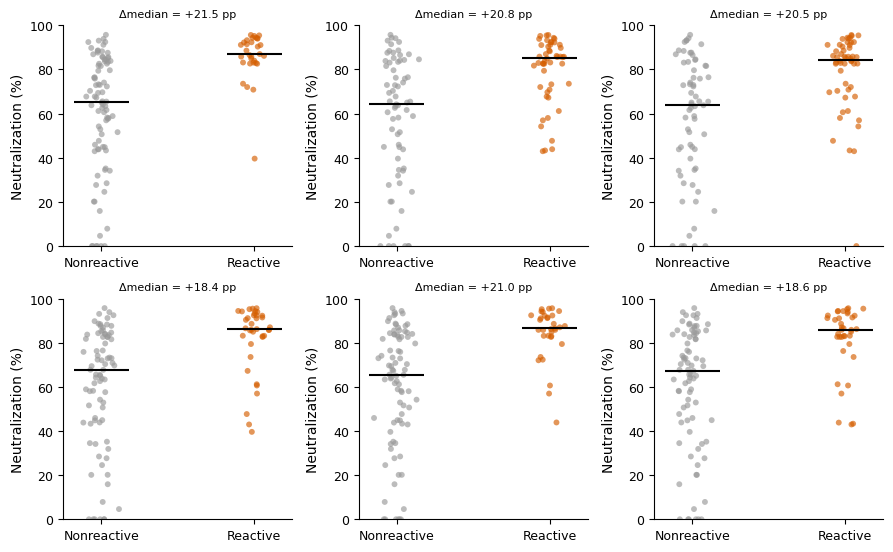

In [9]:
# Plot up to 6 strongest POSITIVE candidates.
# Prefer positive GP-ELISA-adjusted hits; then positive adjusted hits; then positive discovery hits.
ranked = neutralization_results.copy()
ranked['candidate_tier'] = np.select(
    [
        ranked['positive_GP_adjusted_FDR05'].fillna(False),
        ranked['positive_adjusted_FDR05'].fillna(False),
        ranked['positive_FDR05'].fillna(False),
    ],
    [1, 2, 3],
    default=9
)
ranked['rank_metric'] = ranked['FDR_GP_adjusted'].fillna(
    ranked['FDR_adjusted'].fillna(ranked['FDR_screen'])
)
ranked = ranked.loc[ranked['candidate_tier'] < 9].sort_values(
    ['candidate_tier','rank_metric','delta_median_neut'], ascending=[True,True,False]
)

top_peptides = ranked['peptide'].head(6).tolist()
print('Top positive candidates:', top_peptides)

if len(top_peptides):
    plot_long = lasv_neut.loc[lasv_neut['peptide'].isin(top_peptides)].copy()
    plot_long['reactivity'] = np.where(plot_long['reactive'].astype(bool), 'Reactive', 'Nonreactive')

    ncols = min(3, len(top_peptides))
    nrows = int(np.ceil(len(top_peptides)/ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.0*ncols, 2.8*nrows), squeeze=False)
    axes = axes.flat
    rng = np.random.default_rng(42)

    for ax, pep in zip(axes, top_peptides):
        g = plot_long.loc[plot_long['peptide']==pep].drop_duplicates('individual').dropna(subset=['Neut_Percent'])
        for xpos, state in enumerate(['Nonreactive','Reactive']):
            vals = g.loc[g['reactivity']==state,'Neut_Percent'].to_numpy()
            x = xpos + rng.normal(0,0.05,len(vals))
            ax.scatter(x, vals, s=18, alpha=0.65,
                       color=SURVIVOR_COLOR if state=='Reactive' else '0.60', edgecolor='none')
            if len(vals):
                ax.hlines(np.median(vals), xpos-0.18, xpos+0.18, color='black', lw=1.5)
        rr = ranked.set_index('peptide').loc[pep]
        ax.set_xticks([0,1], ['Nonreactive','Reactive'])
        ax.set_ylabel('Neutralization (%)')
        ax.set_title(f"Δmedian = +{rr['delta_median_neut']:.1f} pp", fontsize=8)
        ax.set_ylim(0,100)

    for ax in list(axes)[len(top_peptides):]:
        ax.axis('off')
    fig.tight_layout()
    fig.savefig(OUTDIR/'GPC_neutralization_positive_candidate_peptides.svg', bbox_inches='tight')
    plt.show()
else:
    print('No positive FDR-supported peptide candidates to plot.')


## 4. GPC sequence/region clustering export
Significant positive GPC peptide hits may be overlapping peptides or strain variants representing the same biological epitope. The table below is therefore intended for mapping to the Josiah GPC reference and collapsing sequence-related hits into candidate GP1/GP2 regions.


In [10]:
# Positive-direction candidate table for sequence/region clustering.
# Keep candidates with positive effect and FDR < 0.10 in at least one analysis.
candidate_table = neutralization_results.loc[
    (
        ((neutralization_results['FDR_screen'] < 0.10) & (neutralization_results['delta_median_neut'] > 0)) |
        ((neutralization_results['FDR_adjusted'] < 0.10) & (neutralization_results['beta_adjusted'] > 0)) |
        ((neutralization_results['FDR_GP_adjusted'] < 0.10) & (neutralization_results['beta_GP_adjusted'] > 0))
    )
].copy()

cols = [
    'peptide','protein_std','sequence','accession','n_reactive',
    'median_neut_reactive','median_neut_nonreactive','delta_median_neut','FDR_screen',
    'beta_adjusted','ci_low_adjusted','ci_high_adjusted','FDR_adjusted',
    'beta_GP_adjusted','ci_low_GP_adjusted','ci_high_GP_adjusted','FDR_GP_adjusted'
]

display(candidate_table[cols].sort_values(
    ['protein_std','FDR_GP_adjusted','FDR_adjusted','FDR_screen'], na_position='last'
))

neutralization_results.to_csv(OUTDIR/'LASV_GPC_neutralization_all_peptide_results.csv', index=False)
candidate_table[cols].to_csv(OUTDIR/'LASV_GPC_neutralization_positive_candidate_peptides.csv', index=False)


,peptide,protein_std,sequence,accession,n_reactive,median_neut_reactive,median_neut_nonreactive,delta_median_neut,FDR_screen,beta_adjusted,ci_low_adjusted,ci_high_adjusted,FDR_adjusted,beta_GP_adjusted,ci_low_GP_adjusted,ci_high_GP_adjusted,FDR_GP_adjusted
0,AZI96412.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPKCWLVSNGS,AZI96412.1,31,86.988617,65.452147,21.536470,3.649627e-07,26.011778,17.050647,34.972910,1.913937e-07,21.335942,12.916147,29.755737,0.000010
2,AZI96476.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTITGKTSLPRCWLVSNGS,AZI96476.1,37,86.166650,67.722491,18.444158,5.867396e-06,19.284130,9.895684,28.672577,2.112093e-04,15.555046,6.611577,24.498515,0.002446
5,XBA96065.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,KCNEKHDEEFCDMLRLFDFNKQAIQRLKAEAQMSIQLINKAVNALI,XBA96065.1,52,84.484379,63.994275,20.490105,3.428517e-05,20.066011,9.885608,30.246414,2.398365e-04,16.984681,7.658320,26.311043,0.002446
6,ANH09740.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,CNEKHDEEFCDMWRLFDFNKQAIQRLKAEAQMNIQLINKAVNALIN,ANH09740.1,49,84.984398,64.203796,20.780602,3.428517e-05,19.063439,8.650042,29.476835,6.247065e-04,16.848853,7.276774,26.420932,0.002446
1,AZI96059.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,NDQLIMKNHLRDIMGIPYCNYSKYWYLNNTVTGKSSLPKCWLVSNG,AZI96059.1,33,86.533287,65.563298,20.969990,3.236191e-06,20.135499,10.762715,29.508282,1.910372e-04,15.082625,6.171680,23.993570,0.002726
8,AZI96059.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,YWYLNNTVTGKSSLPKCWLVSNGSYLNETHFSEDIEQQADNMITEM,AZI96059.1,18,87.908520,69.534578,18.373942,6.091204e-05,18.986541,9.477915,28.495167,2.273277e-04,13.116400,4.341977,21.890823,0.007267
3,AZI96488.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPRCWLVSNGT,AZI96488.1,37,85.841573,67.242783,18.598790,1.510129e-05,17.521729,7.629231,27.414227,8.625499e-04,13.970137,4.699113,23.241161,0.007267
4,AHC95553.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,TSLPKCWLVSNGSYLNETHFSDDIEQQADNMITEMLQKEYMDRQGK,AHC95553.1,24,87.618931,68.569823,19.049108,2.076438e-05,18.639160,9.448512,27.829807,2.112093e-04,11.093998,2.346765,19.841232,0.024237
9,AZI96476.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,WYLNHTITGKTSLPRCWLVSNGSYLNETQFSDDIEQQADNMITELL,AZI96476.1,23,86.988617,70.310479,16.678138,8.814540e-04,17.358280,7.009579,27.706980,1.516088e-03,9.782466,0.264312,19.300621,0.073281
11,AHC95553.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,SSNLYKGVYELQSLDLNMETLNMTMPLSCTKNNSHHYIRVGNETGL,AHC95553.1,6,85.075505,73.126483,11.949022,1.050028e-01,14.462397,2.820842,26.103951,2.031378e-02,11.685160,0.034798,23.335522,0.073979


## Interpretation guide
- **Screen FDR**: two-sided GPC peptide-reactive vs nonreactive comparison, corrected across all tested LASV GPC peptides.
- **Positive candidate**: FDR-supported GPC peptide with higher neutralization among peptide-reactive survivors (`delta_median_neut > 0`).
- **Adjusted beta**: estimated percentage-point difference in neutralization associated with GPC peptide reactivity after adjustment for age, sex, and years since discharge. Positive beta is the direction of interest.
- **GP-ELISA-adjusted beta**: secondary model additionally controlling for `ln(1 + GP ELISA concentration)`. Persistence supports an association with peptide specificity beyond overall GP-binding magnitude.
- Directional filtering occurs only after FDR correction. Negative-direction results remain in the full exported table but are not promoted as neutralization-enhancing candidates.


## 5. Next analysis: collapse positive GPC hits into candidate GP1/GP2 regions
Map the positive GPC candidates to the Josiah GPC reference, inspect sequence overlap/similarity, and define biological regions. Then test whether recognition of **any peptide in a region** is associated with higher neutralization. This avoids treating near-identical strain variants as independent epitopes.


In [11]:
# Inspect positive candidates before defining biological regions.
region_seed = candidate_table[
    ['peptide','protein_std','sequence','accession','delta_median_neut','FDR_screen',
     'beta_adjusted','FDR_adjusted','beta_GP_adjusted','FDR_GP_adjusted']
].sort_values(['protein_std','FDR_screen'])

display(region_seed)

# Optional: save for alignment / reference mapping.
region_seed.to_csv(OUTDIR/'LASV_GPC_neutralization_positive_region_seed.csv', index=False)


,peptide,protein_std,sequence,accession,delta_median_neut,FDR_screen,beta_adjusted,FDR_adjusted,beta_GP_adjusted,FDR_GP_adjusted
0,AZI96412.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPKCWLVSNGS,AZI96412.1,21.536470,3.649627e-07,26.011778,1.913937e-07,21.335942,0.000010
1,AZI96059.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,NDQLIMKNHLRDIMGIPYCNYSKYWYLNNTVTGKSSLPKCWLVSNG,AZI96059.1,20.969990,3.236191e-06,20.135499,1.910372e-04,15.082625,0.002726
2,AZI96476.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTITGKTSLPRCWLVSNGS,AZI96476.1,18.444158,5.867396e-06,19.284130,2.112093e-04,15.555046,0.002446
3,AZI96488.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPRCWLVSNGT,AZI96488.1,18.598790,1.510129e-05,17.521729,8.625499e-04,13.970137,0.007267
4,AHC95553.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,TSLPKCWLVSNGSYLNETHFSDDIEQQADNMITEMLQKEYMDRQGK,AHC95553.1,19.049108,2.076438e-05,18.639160,2.112093e-04,11.093998,0.024237
5,XBA96065.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,KCNEKHDEEFCDMLRLFDFNKQAIQRLKAEAQMSIQLINKAVNALI,XBA96065.1,20.490105,3.428517e-05,20.066011,2.398365e-04,16.984681,0.002446
6,ANH09740.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,CNEKHDEEFCDMWRLFDFNKQAIQRLKAEAQMNIQLINKAVNALIN,ANH09740.1,20.780602,3.428517e-05,19.063439,6.247065e-04,16.848853,0.002446
7,AZI96488.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,WYLNHTVTGKTSLPRCWLVSNGTYLNETHFSDDIEQQADNMITELL,AZI96488.1,18.161230,3.428517e-05,15.899571,6.625051e-02,12.310259,0.158629
8,AZI96059.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,YWYLNNTVTGKSSLPKCWLVSNGSYLNETHFSEDIEQQADNMITEM,AZI96059.1,18.373942,6.091204e-05,18.986541,2.273277e-04,13.116400,0.007267
9,AZI96476.1|precursor|Mammarenavirus_lassaense|...,glycoprotein,WYLNHTITGKTSLPRCWLVSNGSYLNETQFSDDIEQQADNMITELL,AZI96476.1,16.678138,8.814540e-04,17.358280,1.516088e-03,9.782466,0.073281


In [12]:
from Bio import SeqIO
from Bio.Align import PairwiseAligner, substitution_matrices
from pathlib import Path

REF_FASTA = Path(
    './ref_seqs/UP000002473_11622_LASV_Josiah_reference.fasta'
)

records = list(SeqIO.parse(REF_FASTA, 'fasta'))

for r in records:
    print(r.id, len(r.seq), r.description)

sp|O09705|L_LASSJ 2218 sp|O09705|L_LASSJ RNA-directed RNA polymerase L OS=Lassa virus (strain Mouse/Sierra Leone/Josiah/1976) OX=11622 GN=L PE=3 SV=1
sp|O73557|Z_LASSJ 99 sp|O73557|Z_LASSJ RING finger protein Z OS=Lassa virus (strain Mouse/Sierra Leone/Josiah/1976) OX=11622 GN=Z PE=1 SV=4
sp|P08669|GLYC_LASSJ 491 sp|P08669|GLYC_LASSJ Pre-glycoprotein polyprotein GP complex OS=Lassa virus (strain Mouse/Sierra Leone/Josiah/1976) OX=11622 GN=GPC PE=1 SV=1
sp|P13699|NCAP_LASSJ 569 sp|P13699|NCAP_LASSJ Nucleoprotein OS=Lassa virus (strain Mouse/Sierra Leone/Josiah/1976) OX=11622 GN=N PE=1 SV=1


In [13]:
reference_by_protein = {
    'polymerase': str(next(r.seq for r in records if 'O09705' in r.id)),
    'glycoprotein': str(next(r.seq for r in records if 'P08669' in r.id)),
    'nucleoprotein': str(next(r.seq for r in records if 'P13699' in r.id)),
    'z protein': str(next(r.seq for r in records if 'O73557' in r.id)),
}


In [14]:
gpc_ref = reference_by_protein['glycoprotein']

In [15]:
print(len(gpc_ref))
print(gpc_ref[:60])

491
MGQIVTFFQEVPHVIEEVMNIVLIALSVLAVLKGLYNFATCGLVGLVTFLLLCGRSCTTS


In [16]:
aligner = PairwiseAligner()

aligner.mode = 'local'
aligner.substitution_matrix = substitution_matrices.load('BLOSUM62')

aligner.open_gap_score = -10
aligner.extend_gap_score = -0.5

In [17]:
def map_peptide_to_reference(peptide_seq, reference_seq, aligner=aligner):
    peptide_seq = str(peptide_seq).upper()
    reference_seq = str(reference_seq).upper()

    alignments = aligner.align(reference_seq, peptide_seq)
    if len(alignments) == 0:
        return None

    aln = alignments[0]
    ref_blocks, pep_blocks = aln.aligned
    if len(ref_blocks) == 0:
        return None

    ref_positions = []
    for (ref_start, ref_end), (pep_start, pep_end) in zip(ref_blocks, pep_blocks):
        ref_positions.extend(range(int(ref_start) + 1, int(ref_end) + 1))

    aligned_length = sum(int(end - start) for start, end in pep_blocks)

    return {
        'ref_start': int(ref_positions[0]),
        'ref_end': int(ref_positions[-1]),
        'ref_positions': ref_positions,
        'aligned_length': aligned_length,
        'alignment_score': float(aln.score),
    }


In [18]:
# Significant positive-direction GPC hits from the discovery screen
gpc_positive_hits = positive_hits.copy()

print(f"{len(gpc_positive_hits)} GPC peptides significantly associated with higher neutralization")
display(gpc_positive_hits[['peptide','sequence','accession','n_reactive','n_nonreactive','median_neut_reactive','median_neut_nonreactive','delta_median_neut','FDR_screen']])


11 GPC peptides significantly associated with higher neutralization


,peptide,sequence,accession,n_reactive,n_nonreactive,median_neut_reactive,median_neut_nonreactive,delta_median_neut,FDR_screen
0,AZI96412.1|precursor|Mammarenavirus_lassaense|...,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPKCWLVSNGS,AZI96412.1,31,87,86.988617,65.452147,21.536470,3.649627e-07
1,AZI96059.1|precursor|Mammarenavirus_lassaense|...,NDQLIMKNHLRDIMGIPYCNYSKYWYLNNTVTGKSSLPKCWLVSNG,AZI96059.1,33,85,86.533287,65.563298,20.969990,3.236191e-06
2,AZI96476.1|precursor|Mammarenavirus_lassaense|...,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTITGKTSLPRCWLVSNGS,AZI96476.1,37,81,86.166650,67.722491,18.444158,5.867396e-06
3,AZI96488.1|precursor|Mammarenavirus_lassaense|...,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPRCWLVSNGT,AZI96488.1,37,81,85.841573,67.242783,18.598790,1.510129e-05
4,AHC95553.1|precursor|Mammarenavirus_lassaense|...,TSLPKCWLVSNGSYLNETHFSDDIEQQADNMITEMLQKEYMDRQGK,AHC95553.1,24,94,87.618931,68.569823,19.049108,2.076438e-05
6,ANH09740.1|precursor|Mammarenavirus_lassaense|...,CNEKHDEEFCDMWRLFDFNKQAIQRLKAEAQMNIQLINKAVNALIN,ANH09740.1,49,69,84.984398,64.203796,20.780602,3.428517e-05
5,XBA96065.1|precursor|Mammarenavirus_lassaense|...,KCNEKHDEEFCDMLRLFDFNKQAIQRLKAEAQMSIQLINKAVNALI,XBA96065.1,52,66,84.484379,63.994275,20.490105,3.428517e-05
7,AZI96488.1|precursor|Mammarenavirus_lassaense|...,WYLNHTVTGKTSLPRCWLVSNGTYLNETHFSDDIEQQADNMITELL,AZI96488.1,24,94,87.695808,69.534578,18.161230,3.428517e-05
8,AZI96059.1|precursor|Mammarenavirus_lassaense|...,YWYLNNTVTGKSSLPKCWLVSNGSYLNETHFSEDIEQQADNMITEM,AZI96059.1,18,100,87.908520,69.534578,18.373942,6.091204e-05
9,AZI96476.1|precursor|Mammarenavirus_lassaense|...,WYLNHTITGKTSLPRCWLVSNGSYLNETQFSDDIEQQADNMITELL,AZI96476.1,23,95,86.988617,70.310479,16.678138,8.814540e-04


In [19]:
# Map significant positive-neutralization GPC peptides to the Josiah GPC reference
mapped_hits = []

for _, row in gpc_positive_hits.iterrows():
    mapping = map_peptide_to_reference(row['sequence'], gpc_ref)
    if mapping is not None:
        mapped_hits.append({**row.to_dict(), **mapping})

mapped_hits = pd.DataFrame(mapped_hits)

if mapped_hits.empty:
    print('No significant positive-neutralization GPC peptides mapped to Josiah.')
else:
    mapped_hits = mapped_hits.sort_values(['ref_start','ref_end']).reset_index(drop=True)

    def assign_gpc_domain(start, end):
        midpoint = (start + end) / 2
        if midpoint <= 58:
            return 'SSP'
        elif midpoint <= 259:
            return 'GP1'
        return 'GP2'

    mapped_hits['domain'] = mapped_hits.apply(
        lambda r: assign_gpc_domain(r['ref_start'], r['ref_end']), axis=1
    )

    display(mapped_hits[[
        'peptide','sequence','ref_start','ref_end','aligned_length',
        'alignment_score','domain','n_reactive','median_neut_reactive',
        'median_neut_nonreactive','delta_median_neut','FDR_screen'
    ]])


,peptide,sequence,ref_start,ref_end,aligned_length,alignment_score,domain,n_reactive,median_neut_reactive,median_neut_nonreactive,delta_median_neut,FDR_screen
0,XBA96065.1|precursor|Mammarenavirus_lassaense|...,KCNEKHDEEFCDMLRLFDFNKQAIQRLKAEAQMSIQLINKAVNALI,300,345,46,235.0,GP2,52,84.484379,63.994275,20.490105,3.428517e-05
1,ANH09740.1|precursor|Mammarenavirus_lassaense|...,CNEKHDEEFCDMWRLFDFNKQAIQRLKAEAQMNIQLINKAVNALIN,301,346,46,227.0,GP2,49,84.984398,64.203796,20.780602,3.428517e-05
2,AZI96059.1|precursor|Mammarenavirus_lassaense|...,NDQLIMKNHLRDIMGIPYCNYSKYWYLNNTVTGKSSLPKCWLVSNG,346,391,46,247.0,GP2,33,86.533287,65.563298,20.969990,3.236191e-06
3,AZI96412.1|precursor|Mammarenavirus_lassaense|...,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPKCWLVSNGS,347,392,46,256.0,GP2,31,86.988617,65.452147,21.536470,3.649627e-07
4,AZI96476.1|precursor|Mammarenavirus_lassaense|...,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTITGKTSLPRCWLVSNGS,347,392,46,252.0,GP2,37,86.166650,67.722491,18.444158,5.867396e-06
5,AZI96488.1|precursor|Mammarenavirus_lassaense|...,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPRCWLVSNGT,347,392,46,250.0,GP2,37,85.841573,67.242783,18.598790,1.510129e-05
6,AZI96059.1|precursor|Mammarenavirus_lassaense|...,YWYLNNTVTGKSSLPKCWLVSNGSYLNETHFSEDIEQQADNMITEM,369,414,46,235.0,GP2,18,87.908520,69.534578,18.373942,6.091204e-05
7,AZI96488.1|precursor|Mammarenavirus_lassaense|...,WYLNHTVTGKTSLPRCWLVSNGTYLNETHFSDDIEQQADNMITELL,370,415,46,238.0,GP2,24,87.695808,69.534578,18.161230,3.428517e-05
8,AZI96476.1|precursor|Mammarenavirus_lassaense|...,WYLNHTITGKTSLPRCWLVSNGSYLNETQFSDDIEQQADNMITELL,370,415,46,232.0,GP2,23,86.988617,70.310479,16.678138,8.814540e-04
9,UCR17178.1|precursor|Mammarenavirus_lassaense|...,WYLNHTTTGRTSLPRCWLVSNGSYLNETHFSDDIEQQADNMITEML,370,415,46,252.0,GP2,12,87.201079,72.182421,15.018658,4.337351e-03


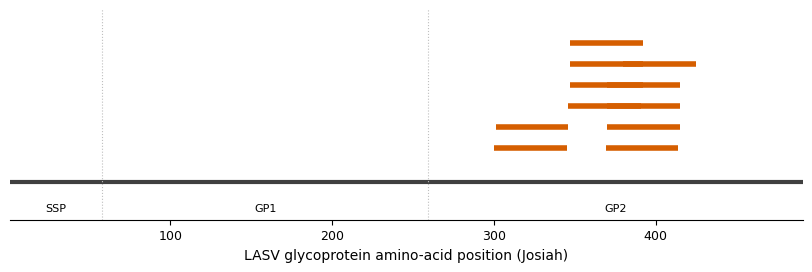

In [20]:
# Visualize significant neutralization-associated peptides on Josiah GPC
if not mapped_hits.empty:
    fig, ax = plt.subplots(figsize=(8.2, 2.8))
    ax.hlines(0, 1, len(gpc_ref), color='0.25', lw=3)
    for x in [58, 259]:
        ax.axvline(x, color='0.75', lw=0.8, ls=':')

    for i, row in mapped_hits.iterrows():
        y = 0.16 + (i % 6) * 0.10
        ax.plot([row['ref_start'], row['ref_end']], [y, y], lw=4, solid_capstyle='butt', color=SURVIVOR_COLOR)

    ax.text(29, -0.10, 'SSP', ha='center', va='top', fontsize=8)
    ax.text((59+259)/2, -0.10, 'GP1', ha='center', va='top', fontsize=8)
    ax.text((260+len(gpc_ref))/2, -0.10, 'GP2', ha='center', va='top', fontsize=8)
    ax.set_xlim(1, len(gpc_ref))
    ax.set_ylim(-0.18, 0.82)
    ax.set_xlabel('LASV glycoprotein amino-acid position (Josiah)')
    ax.set_yticks([])
    ax.spines['left'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    fig.tight_layout()
    plt.show()


In [65]:
def align_full_peptide_to_reference(peptide, reference, aligner):
    """
    Align a peptide to the Josiah GPC reference while preserving
    the full peptide length.

    Returns
    -------
    full_start : inferred 1-based Josiah position of first peptide residue
    full_end   : inferred 1-based Josiah position of last peptide residue
    pep_to_ref : mapping of aligned peptide indices to Josiah positions
    score      : local alignment score
    alignment  : Biopython alignment object
    """

    peptide = str(peptide).upper()
    reference = str(reference).upper()

    alignments = aligner.align(reference, peptide)

    if len(alignments) == 0:
        return None

    aln = alignments[0]

    ref_blocks, pep_blocks = aln.aligned

    if len(ref_blocks) == 0:
        return None

    # peptide residue index -> reference position (1-based)
    pep_to_ref = {}

    for (r0, r1), (p0, p1) in zip(
        ref_blocks,
        pep_blocks
    ):

        block_len = min(
            r1 - r0,
            p1 - p0
        )

        for offset in range(block_len):

            pep_to_ref[p0 + offset] = (
                r0 + offset + 1
            )

    if len(pep_to_ref) == 0:
        return None

    # Use the aligned portion to infer where the COMPLETE
    # peptide starts relative to Josiah.
    mapped_peptide_indices = sorted(
        pep_to_ref.keys()
    )

    first_peptide_index = (
        mapped_peptide_indices[0]
    )

    first_reference_position = (
        pep_to_ref[first_peptide_index]
    )

    # Infer coordinate of peptide residue 0
    full_start = (
        first_reference_position
        - first_peptide_index
    )

    # Preserve complete peptide length
    full_end = (
        full_start
        + len(peptide)
        - 1
    )

    return {
        'alignment': aln,
        'pep_to_ref': pep_to_ref,
        'full_start': int(full_start),
        'full_end': int(full_end),
        'score': aln.score
    }

In [66]:
full_alignments = []

for _, row in positive_hits.iterrows():

    result = align_full_peptide_to_reference(
        row['sequence'],
        gpc_ref,
        aligner
    )

    if result is None:
        continue

    full_alignments.append({
        'peptide': row['peptide'],
        'sequence': row['sequence'],

        # full peptide coordinates inferred from alignment
        'full_start': result['full_start'],
        'full_end': result['full_end'],

        'alignment_score': result['score'],
        'pep_to_ref': result['pep_to_ref'],

        # neutralization statistics
        'delta_median_neut': row['delta_median_neut'],
        'FDR_screen': row['FDR_screen']
    })


full_hits = (
    pd.DataFrame(full_alignments)
    .sort_values(['full_start', 'full_end'])
    .reset_index(drop=True)
)

display(
    full_hits[
        [
            'peptide',
            'full_start',
            'full_end',
            'sequence',
            'delta_median_neut',
            'FDR_screen'
        ]
    ]
)

,peptide,full_start,full_end,sequence,delta_median_neut,FDR_screen
0,XBA96065.1|precursor|Mammarenavirus_lassaense|...,300,345,KCNEKHDEEFCDMLRLFDFNKQAIQRLKAEAQMSIQLINKAVNALI,20.490105,3.428517e-05
1,ANH09740.1|precursor|Mammarenavirus_lassaense|...,301,346,CNEKHDEEFCDMWRLFDFNKQAIQRLKAEAQMNIQLINKAVNALIN,20.780602,3.428517e-05
2,AZI96059.1|precursor|Mammarenavirus_lassaense|...,346,391,NDQLIMKNHLRDIMGIPYCNYSKYWYLNNTVTGKSSLPKCWLVSNG,20.969990,3.236191e-06
3,AZI96412.1|precursor|Mammarenavirus_lassaense|...,347,392,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPKCWLVSNGS,21.536470,3.649627e-07
4,AZI96476.1|precursor|Mammarenavirus_lassaense|...,347,392,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTITGKTSLPRCWLVSNGS,18.444158,5.867396e-06
5,AZI96488.1|precursor|Mammarenavirus_lassaense|...,347,392,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPRCWLVSNGT,18.598790,1.510129e-05
6,AZI96059.1|precursor|Mammarenavirus_lassaense|...,369,414,YWYLNNTVTGKSSLPKCWLVSNGSYLNETHFSEDIEQQADNMITEM,18.373942,6.091204e-05
7,AZI96488.1|precursor|Mammarenavirus_lassaense|...,370,415,WYLNHTVTGKTSLPRCWLVSNGTYLNETHFSDDIEQQADNMITELL,18.161230,3.428517e-05
8,AZI96476.1|precursor|Mammarenavirus_lassaense|...,370,415,WYLNHTITGKTSLPRCWLVSNGSYLNETQFSDDIEQQADNMITELL,16.678138,8.814540e-04
9,UCR17178.1|precursor|Mammarenavirus_lassaense|...,370,415,WYLNHTTTGRTSLPRCWLVSNGSYLNETHFSDDIEQQADNMITEML,15.018658,4.337351e-03


In [67]:
region_start = max(
    1,
    int(full_hits['full_start'].min()) - 5
)

region_end = min(
    len(gpc_ref),
    int(full_hits['full_end'].max()) + 5
)

print(region_start, region_end)

295 430


In [27]:
josiah_region = gpc_ref[
    region_start - 1 : region_end
]

print(josiah_region)

NTAVAKCNEKHDEEFCDMLRLFDFNKQAIQRLKAEAQMSIQLINKAVNALINDQLIMKNHLRDIMGIPYCNYSKYWYLNHTTTGRTSLPKCWLVSNGSYLNETHFSDDIEQQADNMITEMLQKEYMERQGKTPLGL


In [28]:
def make_coordinate_aligned_sequence(
    peptide,
    full_start,
    region_start,
    region_end
):

    width = region_end - region_start + 1

    chars = [' '] * width

    for i, aa in enumerate(peptide):

        ref_pos = int(full_start) + i

        if region_start <= ref_pos <= region_end:

            chars[
                ref_pos - region_start
            ] = aa

    return ''.join(chars)

In [29]:
full_hits['aligned_display'] = full_hits.apply(
    lambda r: make_coordinate_aligned_sequence(
        r['sequence'],
        r['full_start'],
        region_start,
        region_end
    ),
    axis=1
)

In [30]:
print(
    f"Josiah {region_start:>3}  "
    f"{josiah_region}"
)

for i, row in full_hits.iterrows():

    print(
        f"pep {i+1:>2}       "
        f"{row['aligned_display']}"
    )

Josiah 295  NTAVAKCNEKHDEEFCDMLRLFDFNKQAIQRLKAEAQMSIQLINKAVNALINDQLIMKNHLRDIMGIPYCNYSKYWYLNHTTTGRTSLPKCWLVSNGSYLNETHFSDDIEQQADNMITEMLQKEYMERQGKTPLGL
pep  1            KCNEKHDEEFCDMLRLFDFNKQAIQRLKAEAQMSIQLINKAVNALI                                                                                     
pep  2             CNEKHDEEFCDMWRLFDFNKQAIQRLKAEAQMNIQLINKAVNALIN                                                                                    
pep  3                                                          NDQLIMKNHLRDIMGIPYCNYSKYWYLNNTVTGKSSLPKCWLVSNG                                       
pep  4                                                           DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPKCWLVSNGS                                      
pep  5                                                           DQLIMKNHLRDIMGIPYCNYSKYWYLNHTITGKTSLPRCWLVSNGS                                      
pep  6                                                           DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSL

In [31]:
def dot_matches_to_reference(
    aligned_string,
    reference_region
):

    out = []

    for aa, ref_aa in zip(
        aligned_string,
        reference_region
    ):

        if aa == ' ':
            out.append(' ')

        elif aa == ref_aa:
            out.append('.')

        else:
            out.append(aa)

    return ''.join(out)

In [32]:
full_hits['dot_alignment'] = full_hits[
    'aligned_display'
].apply(
    lambda x: dot_matches_to_reference(
        x,
        josiah_region
    )
)

In [33]:
print(
    f"Josiah  {josiah_region}"
)

for i, row in full_hits.iterrows():

    print(
        f"pep {i+1:>2}   "
        f"{row['dot_alignment']}   "
        f"ΔNeut={row['delta_median_neut']:+.1f}  "
        f"FDR={row['FDR_screen']:.3g}"
    )

Josiah  NTAVAKCNEKHDEEFCDMLRLFDFNKQAIQRLKAEAQMSIQLINKAVNALINDQLIMKNHLRDIMGIPYCNYSKYWYLNHTTTGRTSLPKCWLVSNGSYLNETHFSDDIEQQADNMITEMLQKEYMERQGKTPLGL
pep  1        ..............................................                                                                                        ΔNeut=+20.5  FDR=3.43e-05
pep  2         ............W...................N.............                                                                                       ΔNeut=+20.8  FDR=3.43e-05
pep  3                                                      ............................N.V..KS...........                                          ΔNeut=+21.0  FDR=3.24e-06
pep  4                                                       .............................V..K.............                                         ΔNeut=+21.5  FDR=3.65e-07
pep  5                                                       .............................I..K....R........                                         ΔNeut=+18.4

In [35]:
display(
    full_hits[
        [
            'peptide',
            'full_start',
            'full_end',
            'sequence',
            'delta_median_neut',
            'FDR_screen'
        ]
    ].sort_values('full_start')
)

,peptide,full_start,full_end,sequence,delta_median_neut,FDR_screen
0,XBA96065.1|precursor|Mammarenavirus_lassaense|...,300,345,KCNEKHDEEFCDMLRLFDFNKQAIQRLKAEAQMSIQLINKAVNALI,20.490105,3.428517e-05
1,ANH09740.1|precursor|Mammarenavirus_lassaense|...,301,346,CNEKHDEEFCDMWRLFDFNKQAIQRLKAEAQMNIQLINKAVNALIN,20.780602,3.428517e-05
2,AZI96059.1|precursor|Mammarenavirus_lassaense|...,346,391,NDQLIMKNHLRDIMGIPYCNYSKYWYLNNTVTGKSSLPKCWLVSNG,20.969990,3.236191e-06
3,AZI96412.1|precursor|Mammarenavirus_lassaense|...,347,392,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPKCWLVSNGS,21.536470,3.649627e-07
4,AZI96476.1|precursor|Mammarenavirus_lassaense|...,347,392,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTITGKTSLPRCWLVSNGS,18.444158,5.867396e-06
5,AZI96488.1|precursor|Mammarenavirus_lassaense|...,347,392,DQLIMKNHLRDIMGIPYCNYSKYWYLNHTVTGKTSLPRCWLVSNGT,18.598790,1.510129e-05
6,AZI96059.1|precursor|Mammarenavirus_lassaense|...,369,414,YWYLNNTVTGKSSLPKCWLVSNGSYLNETHFSEDIEQQADNMITEM,18.373942,6.091204e-05
7,AZI96488.1|precursor|Mammarenavirus_lassaense|...,370,415,WYLNHTVTGKTSLPRCWLVSNGTYLNETHFSDDIEQQADNMITELL,18.161230,3.428517e-05
8,AZI96476.1|precursor|Mammarenavirus_lassaense|...,370,415,WYLNHTITGKTSLPRCWLVSNGSYLNETQFSDDIEQQADNMITELL,16.678138,8.814540e-04
9,UCR17178.1|precursor|Mammarenavirus_lassaense|...,370,415,WYLNHTTTGRTSLPRCWLVSNGSYLNETHFSDDIEQQADNMITEML,15.018658,4.337351e-03


In [36]:
hits = full_hits.sort_values(
    ['full_start', 'full_end']
).copy()

regions = []
current = None

for _, row in hits.iterrows():

    if current is None:
        current = {
            'start': row['full_start'],
            'end': row['full_end'],
            'peptides': [row['peptide']]
        }

    elif row['full_start'] <= current['end']:
        # overlaps current region
        current['end'] = max(
            current['end'],
            row['full_end']
        )
        current['peptides'].append(row['peptide'])

    else:
        regions.append(current)

        current = {
            'start': row['full_start'],
            'end': row['full_end'],
            'peptides': [row['peptide']]
        }

if current is not None:
    regions.append(current)

region_summary = pd.DataFrame([
    {
        'region': f'GPC_region_{i+1}',
        'start': r['start'],
        'end': r['end'],
        'n_peptides': len(r['peptides']),
        'peptides': r['peptides']
    }
    for i, r in enumerate(regions)
])

display(region_summary)

,region,start,end,n_peptides,peptides
0,GPC_region_1,300,425,11,[XBA96065.1|precursor|Mammarenavirus_lassaense...
